In [1]:
from ngsolve import *

from ngsolve.webgui import Draw
from netgen.csg import *

from netgen.occ import *
from netgen.meshing import IdentificationType

import numpy as np
import matplotlib.pyplot as plt

In [2]:
box_width = 1000
sphere_radius = 10
dipole_d = 25
charge = 0.01

maxh = 50

center = np.array([0.5 * box_width, 0.5 * box_width, 0.5 * box_width])
d_vec = np.array([0.0, 0.0, dipole_d])
neg_position = center - 0.5 * d_vec
pos_position = center + 0.5 * d_vec 

vacuum = Box(Pnt(0,0,0), Pnt(box_width, box_width, box_width))

#sphere = Box(Pnt(0, 0, 0.5*box_width), Pnt(0.5*box_width, 0.5*box_width, 0.5*box_width + sphere_radius))

neg_sphere = Sphere(Pnt(neg_position[0], neg_position[1], neg_position[2]), sphere_radius)
pos_sphere = Sphere(Pnt(pos_position[0], pos_position[1], pos_position[2]), sphere_radius)



test_surface = Box(Pnt(0,0,0.35*box_width), Pnt(box_width, box_width, 0.45*box_width))



vacuum -= neg_sphere
vacuum -= pos_sphere
vacuum -= test_surface

vacuum.mat("vac");

pos_sphere.mat("pos_sph");
neg_sphere.mat("neg_sph");

test_surface.mat("vac");


vacuum.faces.Min(X).name = "b0"
vacuum.faces.Max(X).name = "b1"
vacuum.faces.Min(Y).name = "b2"
vacuum.faces.Max(Y).name = "b3"
vacuum.faces.Min(Z).name = "b4"
vacuum.faces.Max(Z).name = "b5"

geo = OCCGeometry([vacuum, pos_sphere, neg_sphere, test_surface])


mesh = Mesh(geo.GenerateMesh(maxh=maxh)).Curve(3)

In [3]:
Draw(mesh)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

BaseWebGuiScene

In [3]:
eps_dict = {"vac" : 1.0 , "pos_sph" : 1.0, "neg_sph" : 1.0}

In [ ]:
bound_dict = {'b0' :0, 'b1' :0, 'b2' :0, 'b3' :0, 'b4' :0, 'b5' :0}

fes = H1(mesh, order=2, dirichlet="b0|b1|b2|b3|b4|b5")   

gfu  = GridFunction(fes)
gfud = mesh.BoundaryCF( bound_dict, default=0)
gfu.Set(gfud, BND)

fesQ   = L2(mesh, order=2, definedon=mesh.Materials("neg_sph|pos_sph")) # trying H1

dipole_charges = {
    "pos_sph": charge,
    "neg_sph": -charge,
    "vac": 0.0
}

cf_dipole = mesh.MaterialCF(dipole_charges, default=0)


gfQ = GridFunction(fesQ)
gfQ.Set(cf_dipole)

print ("ndof=", fes.ndof)

ndof= 56621


In [6]:
Integrate(gfQ, mesh=mesh.Materials("neg_sph|pos_sph"))

4.89870698888728e-06

In [7]:
pow(sphere_radius,3) * (4/3)*np.pi * 0.01

41.88790204786391

In [8]:
Draw(gfQ, mesh.Materials("pos_sph|neg_sph"))

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

BaseWebGuiScene

In [5]:
epsr = mesh.MaterialCF( eps_dict )


u, v = fes.TnT()
a = BilinearForm(epsr * grad(u) * grad(v) * dx).Assemble() 
gfu  = GridFunction(fes)

In [10]:
Draw(gfu)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

BaseWebGuiScene

In [6]:

f   = LinearForm( gfQ * v * dx("pos_sph|neg_sph")).Assemble()


inv = a.mat.Inverse(freedofs=fes.FreeDofs(), inverse="sparsecholesky")

res = (a.mat * gfu.vec - f.vec).Evaluate()

gfu.vec.data -= inv * res


In [12]:
Draw(gfu)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

BaseWebGuiScene

In [7]:
thetas = [0, np.pi/2, np.pi/4, np.pi/6, np.pi/20, np.pi/2 * 0.99] # 0, 90, 45, 30, 9, almost 45 degrees
center = np.array([0.5*box_width, 0.5*box_width, 0.5*box_width])
R = sphere_radius

rvals_theta_0 = np.linspace(R + dipole_d/2, box_width/2, 200)  # extend into vacuum
rvals_theta_90 = np.linspace(0, box_width/2, 200)
rvals_theta_45 = np.linspace(0, np.sqrt(2) * box_width/2, 200)
rvals_theta_30 = np.linspace(0, (box_width/2)/np.cos(thetas[3]), 200)
rvals_theta_9 = np.linspace(0, (box_width/2)/np.cos(thetas[4]), 200)
rvals_theta_40 = np.linspace(0, (box_width/2)/np.cos(np.pi/2 - thetas[5]), 200)

phivals_theta_0 = []
for r in rvals_theta_0:
    p = center + np.array([0, 0, r])  # z-direction from edge of one sphere
    phivals_theta_0.append(gfu(mesh(*p)))

phivals_theta_90 = []
for r in rvals_theta_90:
    p = center + np.array([0, r * np.sin(thetas[1]), r * np.cos(thetas[1])]) # y-direction from center
    phivals_theta_90.append(gfu(mesh(*p)))

phivals_theta_45 = []
for r in rvals_theta_45:
    p = center + np.array([0, r * np.sin(thetas[2]), r * np.cos(thetas[2])])
    phivals_theta_45.append(gfu(mesh(*p)))

phivals_theta_30 = []
for r in rvals_theta_30:
    p = center + np.array([0, r * np.sin(thetas[3]), r * np.cos(thetas[3])])
    phivals_theta_30.append(gfu(mesh(*p)))

phivals_theta_9 = []
for r in rvals_theta_9:
    p = center + np.array([0, r * np.sin(thetas[4]), r * np.cos(thetas[4])])
    phivals_theta_9.append(gfu(mesh(*p)))

phivals_theta_40 = []
for r in rvals_theta_40:
    p = center + np.array([0, r * np.sin(thetas[5]), r * np.cos(thetas[5])])
    phivals_theta_40.append(gfu(mesh(*p)))

In [8]:
def phi_analytical (r, p, theta, eps_0 = 1):
    return p * np.cos(theta)/(4 * np.pi * eps_0 * r ** 2)

In [9]:
total_charge = 4/3 * np.pi * sphere_radius ** 3 * charge
phivals_analytical_theta_0 = phi_analytical(rvals_theta_0, dipole_d * total_charge, thetas[0])
phivals_analytical_theta_90 = phi_analytical(rvals_theta_90, dipole_d * total_charge, thetas[1])
phivals_analytical_theta_45 = phi_analytical(rvals_theta_45, dipole_d * total_charge, thetas[2])
phivals_analytical_theta_30 = phi_analytical(rvals_theta_30, dipole_d * total_charge, thetas[3])
phivals_analytical_theta_9 = phi_analytical(rvals_theta_9, dipole_d * total_charge, thetas[4])
phivals_analytical_theta_40 = phi_analytical(rvals_theta_40, dipole_d * total_charge, thetas[5])

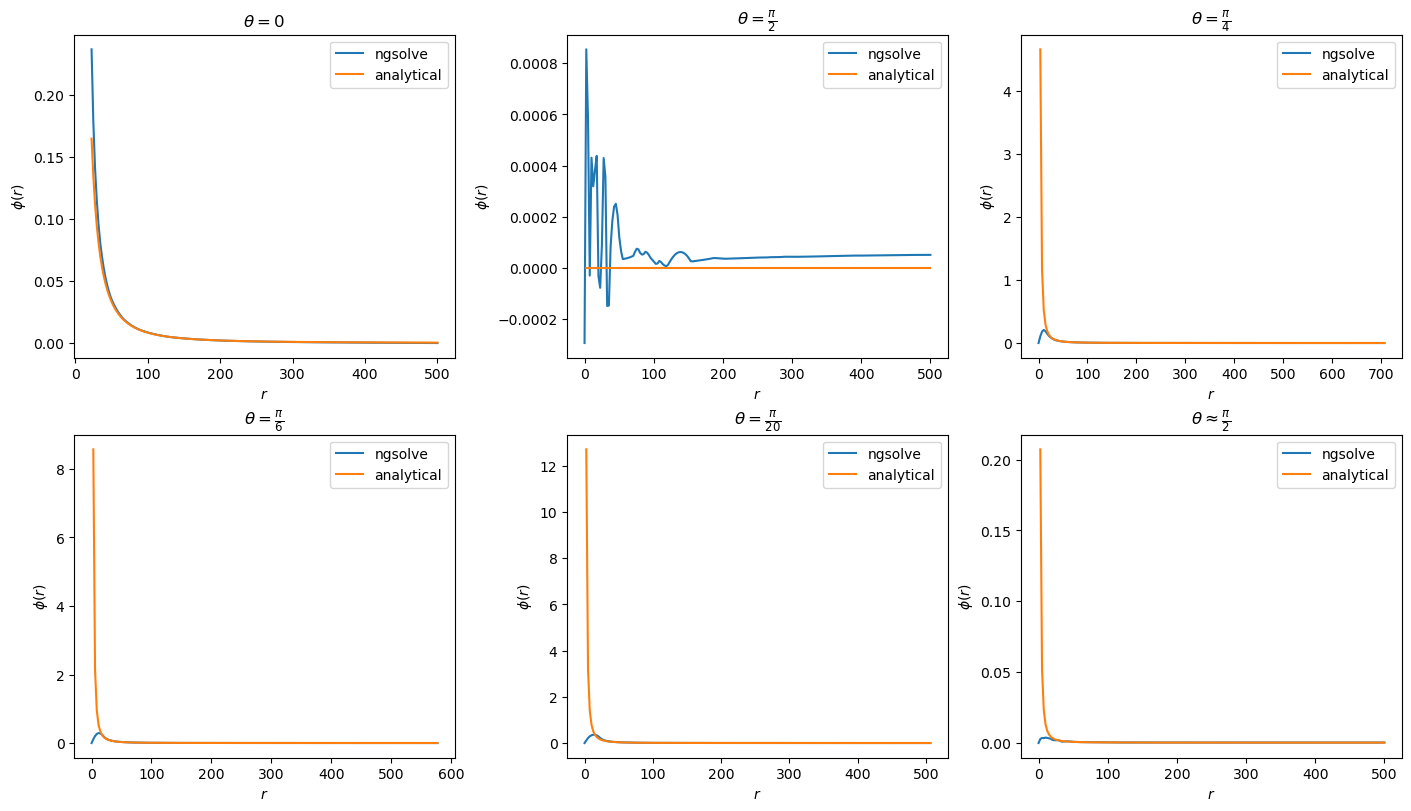

In [10]:
fig, axs = plt.subplots(ncols=3, nrows=2, figsize=(14, 8), layout='constrained')

axs[0,0].plot(rvals_theta_0, phivals_theta_0, label="ngsolve")
axs[0,0].plot(rvals_theta_0, phivals_analytical_theta_0, label="analytical")
axs[0,0].set_title(f'$\\theta=0$')
axs[0,0].set_xlabel('$r$')
axs[0,0].set_ylabel('$\\phi(r)$')
axs[0,0].legend()

axs[0,1].plot(rvals_theta_90, phivals_theta_90, label="ngsolve")
axs[0,1].plot(rvals_theta_90, phivals_analytical_theta_90, label="analytical")
axs[0,1].set_title(f'$\\theta=\\frac{{\\pi}}{{2}}$')
axs[0,1].set_xlabel('$r$')
axs[0,1].set_ylabel('$\\phi(r)$')
axs[0,1].legend()

axs[0,2].plot(rvals_theta_45, phivals_theta_45, label="ngsolve")
axs[0,2].plot(rvals_theta_45, phivals_analytical_theta_45, label="analytical")
axs[0,2].set_title(f'$\\theta=\\frac{{\\pi}}{{4}}$')
axs[0,2].set_xlabel('$r$')
axs[0,2].set_ylabel('$\\phi(r)$')
axs[0,2].legend()

axs[1,0].plot(rvals_theta_30, phivals_theta_30, label="ngsolve")
axs[1,0].plot(rvals_theta_30, phivals_analytical_theta_30, label="analytical")
axs[1,0].set_title(f'$\\theta=\\frac{{\\pi}}{{6}}$')
axs[1,0].set_xlabel('$r$')
axs[1,0].set_ylabel('$\\phi(r)$')
axs[1,0].legend()

axs[1,1].plot(rvals_theta_9, phivals_theta_9, label="ngsolve")
axs[1,1].plot(rvals_theta_9, phivals_analytical_theta_9, label="analytical")
axs[1,1].set_title(f'$\\theta=\\frac{{\\pi}}{{20}}$')
axs[1,1].set_xlabel('$r$')
axs[1,1].set_ylabel('$\\phi(r)$')
axs[1,1].legend()

axs[1,2].plot(rvals_theta_40, phivals_theta_40, label="ngsolve")
axs[1,2].plot(rvals_theta_40, phivals_analytical_theta_40, label="analytical")
axs[1,2].set_title(f'$\\theta\\approx\\frac{{\\pi}}{{2}}$')
axs[1,2].set_xlabel('$r$')
axs[1,2].set_ylabel('$\\phi(r)$')
axs[1,2].legend()




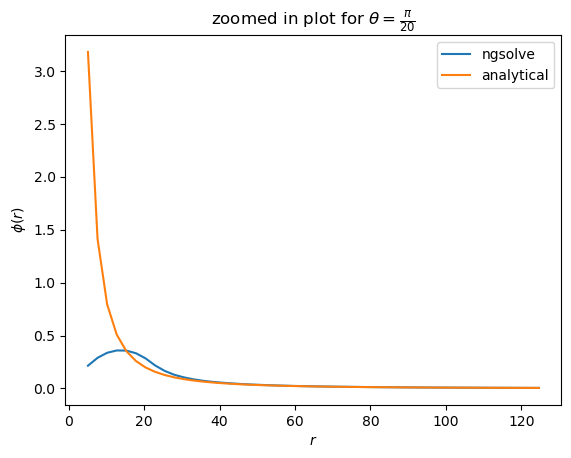

In [11]:
start_idx = 2
end_idx = 50

plt.plot(rvals_theta_9[start_idx:end_idx], phivals_theta_9[start_idx:end_idx], label="ngsolve")
plt.plot(rvals_theta_9[start_idx:end_idx], phivals_analytical_theta_9[start_idx:end_idx], label="analytical")
plt.xlabel('$r$')
plt.ylabel('$\\phi(r)$')
plt.title('zoomed in plot for $\\theta=\\frac{{\\pi}}{{20}}$')
plt.legend()

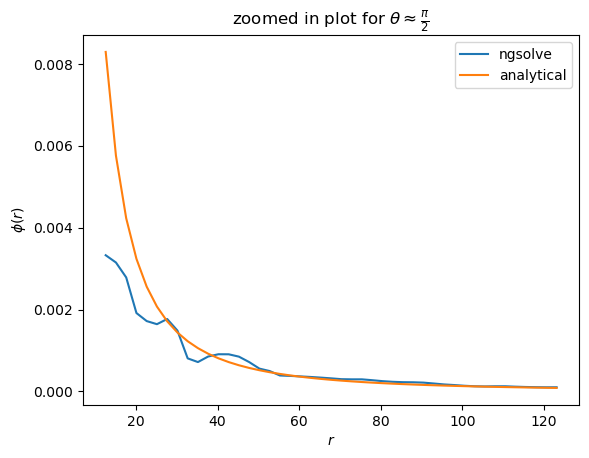

In [12]:
start_idx = 5
end_idx = 50

plt.plot(rvals_theta_40[start_idx:end_idx], phivals_theta_40[start_idx:end_idx], label="ngsolve")
plt.plot(rvals_theta_40[start_idx:end_idx], phivals_analytical_theta_40[start_idx:end_idx], label="analytical")
plt.xlabel('$r$')
plt.ylabel('$\\phi(r)$')
plt.title('zoomed in plot for $\\theta\\approx\\frac{{\\pi}}{{2}}$')
plt.legend()